# PEEP trial segmentation - testing the choices on real recordings

After the preprocessing layer (notebook 05) every recording is an `EITRecording`: breaths, quality flags, lung mask,
regions and the auxiliary signals (pressures). In a PEEP trial the next step is to split the recording by PEEP level:
which breaths belong to each step, and which ones are still in the transition after a change. This is layer 2b: still
preparation of the data, not measurement (the clinical indices come in layer 3).

As in notebook 05, each section is a question, what I tried, and what I decided. Functions written here are
prototypes, not fastEIT code.

| § | Question |
|---|----------|
| 1 | Which recordings am I using? |
| 2 | Where can the PEEP of each breath come from? |
| 3 | How do I find the steps from the airway pressure? |
| 4 | How long is the transition after a PEEP change? |
| 5 | Without a pressure signal, can I find the steps from EELI? |
| 6 | Decisions |

The recordings are not in the repository. Times are seconds from the start of each recording.

*Research use only - not a medical device.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess

TEST_FILES = Path("../src/fasteit/test_files")
FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))

BLUE, ORANGE, GREY, INK = "#3987e5", "#e8730c", "#9a9a9a", "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})


def event_texts(raw, time):
    """(time in s, text) of every Draeger event marker."""
    frames = raw.frames
    changes = np.flatnonzero(np.diff(frames["event_marker"]) != 0) + 1
    return [(float(time[i]), frames["event_text"][i].split(b"\x00")[0].decode(errors="replace").strip())
            for i in changes]


recordings, events = {}, {}
for path in FILES:
    name = path.stem.replace("PEEP_trial_", "")
    raw = load_data(path)
    recordings[name] = preprocess(raw)
    events[name] = event_texts(raw, recordings[name].time)
list(recordings)

['A_park_bench', 'A_supine', 'B_park_bench', 'B_supine']

## 1. Which recordings am I using?

Four decremental PEEP trials from two patients (A and B), each one supine and in park bench position: PEEP from 16 to
0 cmH2O in steps of 2, volume-controlled ventilation, intubated patients. Each step was annotated by hand in the Dräger
event texts. The airway pressure comes from the PressurePod; the ventilator was not connected through Medibus.

In [2]:
pd.DataFrame(
    {
        name: {
            "duration (s)": round(rec.time[-1]),
            "fs (Hz)": rec.fs,
            "breaths": len(rec.breaths),
            "valid breaths": int(rec.breaths.is_valid.sum()),
            "annotated events": len(events[name]),
            "auxiliary channels": ", ".join(c for c in rec.aux.columns if c not in ("min_max_flag", "event_marker")),
        }
        for name, rec in recordings.items()
    }
).T

,duration (s),fs (Hz),breaths,valid breaths,annotated events,auxiliary channels
A_park_bench,519,50.0,98,95,14,airway_pressure_pod
A_supine,591,50.0,131,127,9,airway_pressure_pod
B_park_bench,600,50.0,182,179,10,airway_pressure_pod
B_supine,600,50.0,195,194,10,airway_pressure_pod


## 2. Where can the PEEP of each breath come from?

Four possible sources:

- **Medibus `peep`**: the value computed by the ventilator. Not available here (no ventilator connected).
- **Event texts**: written by hand at the bedside. They give the nominal PEEP of each step.
- **Airway pressure (`airway_pressure_pod`)**: the measured pressure, frame by frame.
- **EELI**: it follows the PEEP, but it does not give a pressure value (§5).

### Event texts

In [3]:
pd.DataFrame(
    [(name, round(t, 1), text) for name, items in events.items() for t, text in items],
    columns=["trial", "time (s)", "text"],
).set_index(["trial", "time (s)"])

text
trial        time (s)                           
A_park_bench 5.6              park bench peep 16
             51.3             park bench peep 14
             95.7             park bench peep 14
             102.5                       peep 12
             133.8                              
             136.9                       peep 10
             166.4                              
             169.9                        peep 8
             224.4                        peep 6
             273.2                              
             275.3                        perp 4
             319.1                        perp 2
             356.6                        perp 0
             423.3                 aop prk bench
A_supine     2.1              supine vcv peep 16
             136.1            supine vcv peep 14
             176.9            supine vcv peep 12
             222.7            supine vcv peep 10
             274.1             supine vcv peep 8
             321.5             supine vcv peep 6
             365.2             supine vcv peep 4
             420.5             supine vcv peep 2
             463.2             supine vcv peep 0
B_park_bench 2.0                      pb 16 peep
             72.4                     pb 14 peep
             150.4                    pb 12 peep
             224.0                    pb 10 peep
             282.0                     pb 8 peep
             337.4                     pb 6 peep
             401.7                      pb 4peep
             450.3                     pb 2 peep
             490.3                     pb 0 peep
             547.9             pb airway closure
B_supine     0.9               supine iot 16peep
             98.6             supine iot 14 peep
             156.1            supine iot 12 peep
             206.9            supine iot 10 peep
             252.6             supine iot 8 peep
             295.8             supine iot 6 peep
             346.3             supine iot 4 peep
             406.1             supine iot 2 peep
             462.8             supine iot 0 peep
             494.3     supine iot airway closure

The texts name the steps, but they are not clean: one step annotated twice (A park bench, "peep 14"), events
without text, typing errors ("perp 4"), and the maneuvers at the end of the trial ("aop", "airway closure") in the same
list as the steps. In §3 I also check when they were written compared with the real change of pressure.

### Where to read the PEEP of a breath on the pressure curve

The simplest choice is the airway pressure at the start of the breath (the EIT valley). Looking at the curves, the EIT
valley often comes a few tenths of a second after the pressure has already started to rise, and at the end of
expiration the pressure has small oscillations. So I read the PEEP on the pressure curve itself: **the median pressure
from 0.8 to 0.3 s before the start of the breath**, the flat end of the previous expiration.

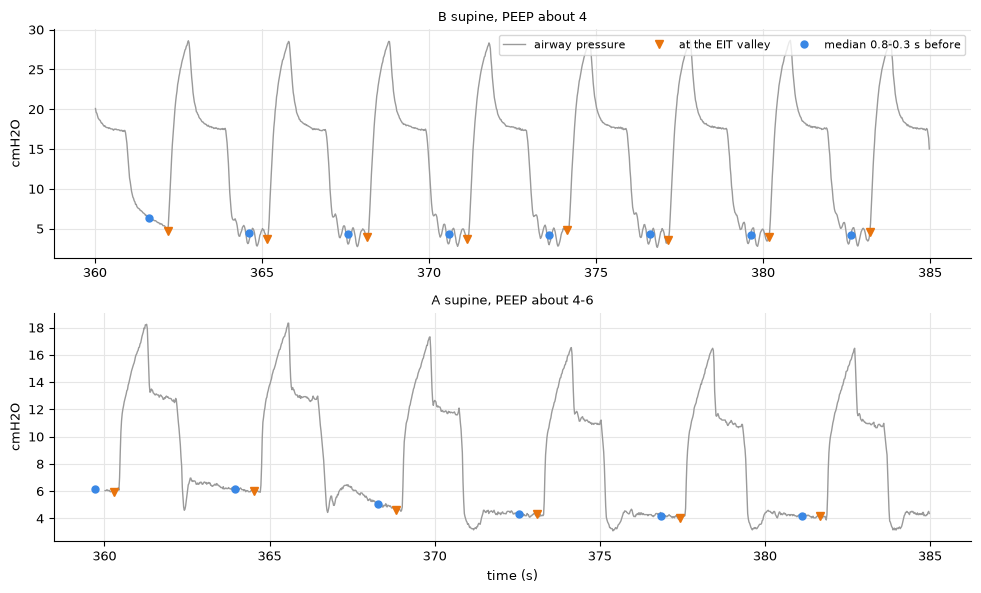

In [4]:
PEEP_WINDOW = (0.8, 0.3)  # seconds before the start of the breath


def breath_peep(paw, fs, starts, window=PEEP_WINDOW):
    """PEEP of each breath: median airway pressure at the end of the previous expiration."""
    first, last = int(round(window[0] * fs)), int(round(window[1] * fs))
    peep = np.full(len(starts), np.nan)
    for i, start in enumerate(starts):
        if start - first >= 0:
            peep[i] = np.nanmedian(paw[start - first : start - last])
    return peep


def show_window(ax, rec, t0, t1, title):
    t, paw = rec.time, rec.aux.airway_pressure_pod.to_numpy()
    shown = (t >= t0) & (t < t1)
    breaths = rec.breaths[(rec.breaths.start_time >= t0) & (rec.breaths.start_time < t1)]
    starts = breaths.start_idx.to_numpy()
    ax.plot(t[shown], paw[shown], color=GREY, lw=1, label="airway pressure")
    ax.plot(t[starts], paw[starts], "v", color=ORANGE, ms=6, label="at the EIT valley")
    peep = breath_peep(paw, rec.fs, starts)
    ax.plot(t[starts] - 0.55, peep, "o", color=BLUE, ms=5, label="median 0.8-0.3 s before")
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("cmH2O")


fig, axes = plt.subplots(2, 1, figsize=(10, 6))
show_window(axes[0], recordings["B_supine"], 360, 385, "B supine, PEEP about 4")
show_window(axes[1], recordings["A_supine"], 360, 385, "A supine, PEEP about 4-6")
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

In [5]:
def noise(values):
    """Median breath-to-breath change: small inside a step if the measure is stable."""
    return np.nanmedian(np.abs(np.diff(values)))


rows = []
for name, rec in recordings.items():
    paw, starts = rec.aux.airway_pressure_pod.to_numpy(), rec.breaths.start_idx.to_numpy()
    rows.append({"trial": name,
                 "at the EIT valley": noise(paw[starts]),
                 "median 0.8-0.3 s before": noise(breath_peep(paw, rec.fs, starts))})
pd.DataFrame(rows).set_index("trial").round(2).rename_axis(
    "breath-to-breath change of PEEP (cmH2O, median)", axis=1)

"breath-to-breath change of PEEP (cmH2O, median)",at the EIT valley,median 0.8-0.3 s before
trial,,
A_park_bench,0.15,0.00
A_supine,0.11,0.04
B_park_bench,0.08,0.08
B_supine,0.09,0.05


Reading the pressure at the end of expiration lowers the breath-to-breath noise in three trials (from 0.15
to 0.00 and from 0.11 to 0.04 cmH2O in trial A, from 0.09 to 0.05 in B supine) and leaves it unchanged in B park
bench.

## 3. How do I find the steps from the airway pressure?

A simple rule on the PEEP of each breath: **a new step starts when three breaths in a row are more than 1 cmH2O away
from the level of the current step** (half of a 2 cmH2O step) and agree among themselves. The level of a step is the
median PEEP of its breaths. Requiring three breaths makes a single odd breath (a maneuver, an artifact) unable to open
a step.

In [6]:
STEP_THRESHOLD = 1.0  # cmH2O
STEP_MIN_BREATHS = 3


def find_steps(peep, threshold=STEP_THRESHOLD, min_breaths=STEP_MIN_BREATHS):
    """Index of the first breath of each step."""
    starts, level, i = [0], peep[0], 1
    while i < len(peep):
        window = peep[i : i + min_breaths]
        new_level = (len(window) == min_breaths and np.all(np.abs(window - level) > threshold)
                     and np.ptp(window) < 2 * threshold)
        if new_level:
            starts.append(i)
            level = np.median(window)
            i += min_breaths
        else:
            level = np.nanmedian(peep[starts[-1] : i + 1])
            i += 1
    return np.array(starts)


def breath_table(rec):
    """Breaths with their PEEP, EELI, TIV (global signal, mean of 0.2 s) and step."""
    b = rec.breaths
    starts, peaks = b.start_idx.to_numpy(), b.peak_idx.to_numpy()
    half = int(round(0.1 * rec.fs))
    level = lambda frames: np.array([rec.global_signal[max(0, f - half): f + half + 1].mean() for f in frames])
    table = pd.DataFrame({"time": b.start_time.to_numpy(),
                          "peep": breath_peep(rec.aux.airway_pressure_pod.to_numpy(), rec.fs, starts),
                          "eeli": level(starts)})
    table["tiv"] = level(peaks) - table.eeli
    filled = table.peep.bfill().to_numpy()
    step_starts = find_steps(filled)
    table["step"] = np.searchsorted(step_starts, np.arange(len(table)), side="right") - 1
    table["step_level"] = table.groupby("step").peep.transform("median")
    return table


tables = {name: breath_table(rec) for name, rec in recordings.items()}
steps = pd.concat(
    {name: t.groupby("step").agg(start=("time", "first"), breaths=("peep", "size"), peep=("peep", "median"))
     for name, t in tables.items()},
    names=["trial", "step"],
)
steps.round(1).unstack("trial").loc[:, ["peep"]]

peep                               
trial A_park_bench A_supine B_park_bench B_supine
step                                             
0             16.0     16.0         16.5     16.8
1             14.0     14.1         14.5     14.9
2             12.0     12.2         12.6     13.0
3             10.0     10.1         10.7     10.7
4              8.0      8.1          8.7      8.9
5              6.0      6.2          6.6      6.8
6              4.0      4.2          4.5      4.3
7              2.1      2.2          2.6      2.9
8              0.3      0.6          1.2      1.3

Nine steps in every trial, from 16 to about 0 cmH2O. In trial A the measured PEEP is within 0.2 cmH2O of
the nominal value (0.3-0.6 at PEEP 0); in trial B it is 0.3-1.3 cmH2O above it.

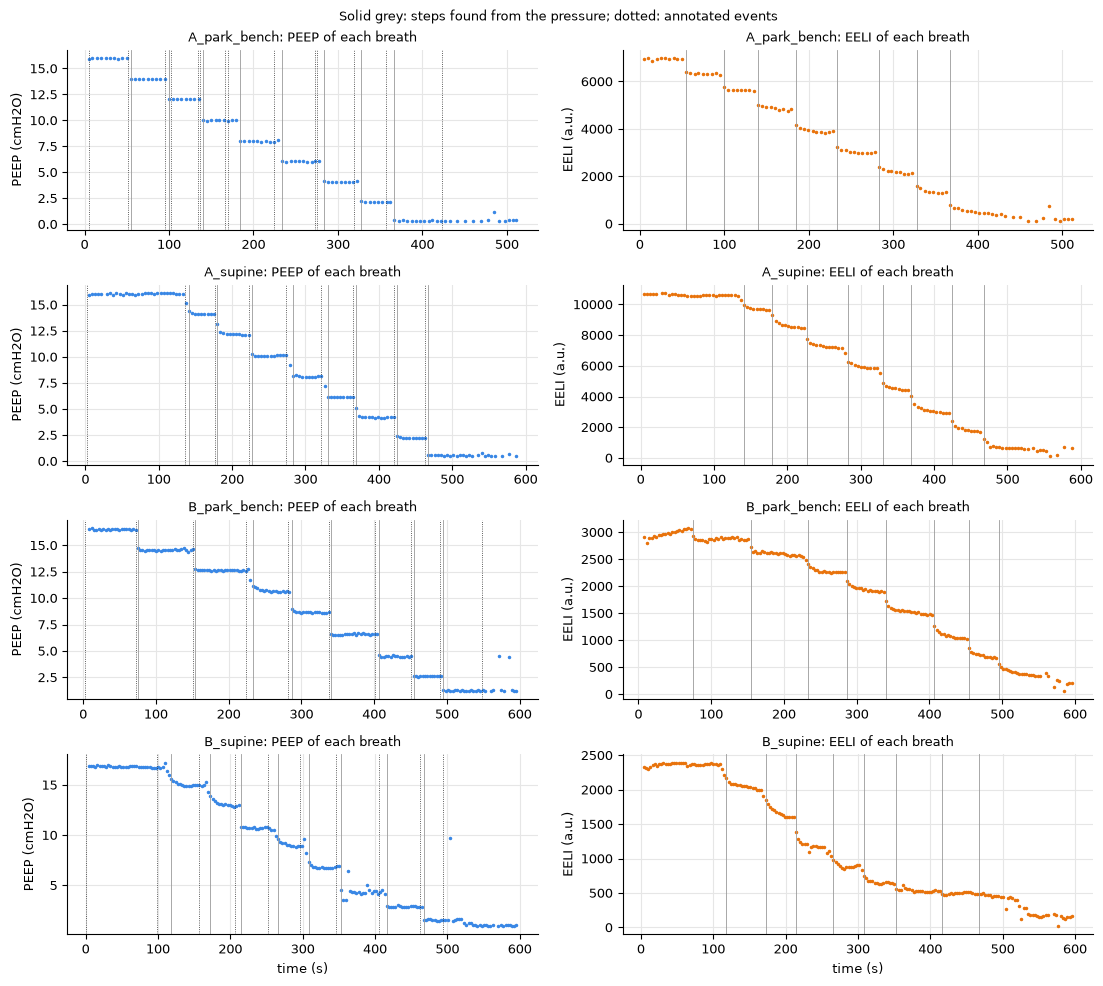

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(11, 10), sharex="row")
for row, (name, t) in enumerate(tables.items()):
    changes = t.time[t.step.diff() > 0]
    for ax, column, color, label in [(axes[row, 0], "peep", BLUE, "PEEP (cmH2O)"),
                                     (axes[row, 1], "eeli", ORANGE, "EELI (a.u.)")]:
        ax.plot(t.time, t[column], ".", ms=3, color=color)
        for x in changes:
            ax.axvline(x, color=GREY, lw=0.6)
        ax.set_ylabel(label)
    for x, text in events[name]:
        axes[row, 0].axvline(x, color=INK, lw=0.6, ls=":")
    axes[row, 0].set_title(f"{name}: PEEP of each breath", fontsize=9)
    axes[row, 1].set_title(f"{name}: EELI of each breath", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
fig.suptitle("Solid grey: steps found from the pressure; dotted: annotated events", fontsize=9)
plt.tight_layout()
plt.show()

### Events compared with the steps found

For each step found I look for the last event written before it (within 30 s) and measure how much earlier it was
written.

In [8]:
rows = []
for name, t in tables.items():
    starts = t.groupby("step").time.first().to_numpy()[1:]
    for start in starts:
        before = [x for x, text in events[name] if start - 30 <= x <= start]
        rows.append({"trial": name, "step start (s)": round(start, 1),
                     "event written before (s)": round(start - before[-1], 1) if before else np.nan})
lead = pd.DataFrame(rows)
lead.groupby("trial")["event written before (s)"].describe()[["count", "min", "50%", "max"]].round(1)

,count,min,50%,max
trial,,,,
A_park_bench,8.0,3.1,8.3,14.6
A_supine,8.0,2.7,4.2,8.7
B_park_bench,8.0,2.7,4.2,9.1
B_supine,8.0,4.5,11.2,19.7


Every change of PEEP found from the pressure has an event written before it, from about 3 s up to about 20 s
earlier (median 4-11 s per trial). Whatever the reason, the events can **name** the steps, but the pressure must
**cut** them.

### Odd breaths inside a step

Breaths with a PEEP more than 1 cmH2O away from the level of their step:

In [9]:
pd.concat({name: t.loc[(t.peep - t.step_level).abs() > STEP_THRESHOLD, ["time", "peep", "step_level"]]
           for name, t in tables.items()}).round(1)

time  peep  step_level
B_park_bench 175  570.9   4.5         1.2
             178  585.3   4.4         1.2
B_supine     119  362.2   6.4         4.3
             166  504.3   9.7         1.3

Four breaths. Three are the end-expiratory plateaus of the airway closure maneuver at the end of trial B. The
fourth (B supine, 362 s) is a breath whose expiration had not ended: the pressure was still falling when the next
inspiration started (first panel of the figure in §2). The "aop" maneuver of trial A does not show up here, so this
check alone does not find the maneuvers: they are better marked as manual exclusions (the user knows when they were
done).

## 4. How long is the transition after a PEEP change?

After each change EELI moves to a new level, and the breaths of the transition should not be analysed. I tried two
ways of defining the end of the transition, both based on the final level of the step (median EELI of its last five
breaths):

- **settling**: the first breath from which EELI stays within 10 % of the tidal variation (TIV) from the final level.
  The scale is the tidal breath, so it does not depend on the units of the image;
- **drift at the end of the step**: the slope of EELI in the last 30 s of the step, in % of TIV per minute.

In [10]:
SETTLE_FRACTION_OF_TIV = 0.10
END_WINDOW_SECONDS = 30

rows = []
for name, t in tables.items():
    for step, s in t.groupby("step"):
        if step == 0:
            continue  # the first step has no change before it
        final, tiv = s.eeli.iloc[-5:].median(), s.tiv.median()
        inside = (s.eeli - final).abs().to_numpy() <= SETTLE_FRACTION_OF_TIV * tiv
        settled = next((i for i in range(len(s)) if inside[i:].all()), len(s))
        end = s[s.time >= s.time.iloc[-1] - END_WINDOW_SECONDS]
        slope = np.polyfit(end.time, end.eeli, 1)[0] * 60
        rows.append({"trial": name, "step": step, "peep": round(s.peep.median(), 1),
                     "step length (s)": round(s.time.iloc[-1] - s.time.iloc[0]), "breaths": len(s),
                     "breaths in last 30 s": len(end),
                     "breaths to settle": settled,
                     "seconds to settle": round(s.time.iloc[min(settled, len(s) - 1)] - s.time.iloc[0], 1),
                     "drift last 30 s (% TIV/min)": round(100 * slope / tiv, 1)})
transitions = pd.DataFrame(rows)
transitions

,trial,step,peep,step length (s),breaths,breaths in last 30 s,breaths to settle,seconds to settle,drift last 30 s (% TIV/min)
0,A_park_bench,1,14.0,40,9,6,0,0.0,-4.1
1,A_park_bench,2,12.0,35,8,6,0,0.0,-6.1
2,A_park_bench,3,10.0,39,9,7,1,4.6,-12.2
3,A_park_bench,4,8.0,44,10,7,1,4.7,-8.2
4,A_park_bench,5,6.0,44,10,7,1,4.7,-3.9
5,A_park_bench,6,4.0,39,9,7,1,4.7,-10.7
6,A_park_bench,7,2.1,35,8,7,1,4.5,-18.5
7,A_park_bench,8,0.3,144,25,6,20,124.2,-48.0
8,A_supine,1,14.1,34,9,7,1,4.3,-10.3
9,A_supine,2,12.2,43,11,7,3,12.8,-16.5


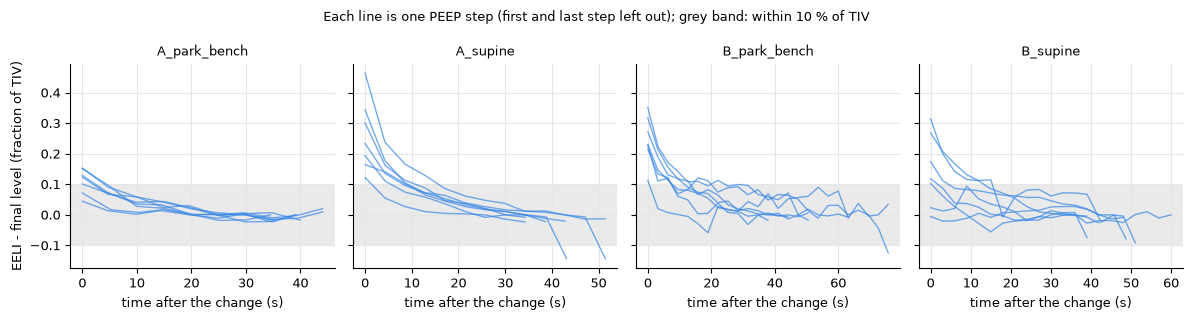

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    for step, s in t.groupby("step"):
        if step == 0 or step == t.step.max():
            continue
        final, tiv = s.eeli.iloc[-5:].median(), s.tiv.median()
        ax.plot(s.time - s.time.iloc[0], (s.eeli - final) / tiv, color=BLUE, lw=1, alpha=0.7)
    ax.axhspan(-SETTLE_FRACTION_OF_TIV, SETTLE_FRACTION_OF_TIV, color=GREY, alpha=0.2, lw=0)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("time after the change (s)")
axes[0].set_ylabel("EELI - final level (fraction of TIV)")
fig.suptitle("Each line is one PEEP step (first and last step left out); grey band: within 10 % of TIV", fontsize=9)
plt.tight_layout()
plt.show()

In [12]:
middle = transitions[transitions.step < transitions.groupby("trial").step.transform("max")]
summary = middle.groupby("trial").agg(
    settle_median_s=("seconds to settle", "median"), settle_max_s=("seconds to settle", "max"),
    never_settled=("breaths to settle", lambda x: int((x == middle.loc[x.index, "breaths"]).sum())),
    breaths_last_30s_min=("breaths in last 30 s", "min"), breaths_last_30s_max=("breaths in last 30 s", "max"),
    drift_min=("drift last 30 s (% TIV/min)", "min"), drift_max=("drift last 30 s (% TIV/min)", "max"),
)
summary.round(1)

,settle_median_s,settle_max_s,never_settled,breaths_last_30s_min,breaths_last_30s_max,drift_min,drift_max
trial,,,,,,,
A_park_bench,4.6,4.7,0,6,7,-18.5,-3.9
A_supine,12.9,51.5,2,7,8,-32.2,-10.3
B_park_bench,12.6,75.8,1,10,10,-23.0,-3.7
B_supine,3.0,18.0,0,10,11,-28.4,3.1


Leaving out the last step (PEEP 0, which contains the maneuvers), EELI settles within 10 % of TIV within a
few breaths in most steps (median 3-13 s per trial), but not always: in three steps (A supine at PEEP 10 and 8,
B park bench at 12.6) it keeps falling until the end of the step (slow derecruitment?), so the step never settles by
this definition. Even in the last 30 s EELI still moves, from -32 % to +3 % of TIV per minute. The transition is
different from patient to patient and from step to step, so a fixed number of breaths would be either too short or
too long, and a settling rule would leave some steps with no breaths at all.

A simpler rule is to keep the last 30 s of each step: here it leaves 6 to 11 breaths per step, and the EELI drift in
that window can be reported with the step, so a step that is still moving is visible instead of hidden.

## 5. Without a pressure signal, can I find the steps from EELI?

When there is no pressure (no PressurePod, no Medibus), the only trace of a PEEP change is the fall of EELI. I tried
the simplest rule: a change where EELI falls by more than a fraction of TIV within three breaths. The steps found
from the pressure are the reference.

In [13]:
def eeli_changes(eeli, tiv, fraction, span=3, min_gap=5):
    """First breath of each fall of EELI larger than `fraction` x median TIV within `span` breaths."""
    drop = eeli[:-span] - eeli[span:]
    found = []
    for i in np.flatnonzero(drop > fraction * np.median(tiv)):
        if not found or i - found[-1] >= min_gap:
            found.append(i)
    return np.array(found) + 1


rows = []
for fraction in (0.2, 0.3, 0.5):
    hits = false = total = 0
    for name, t in tables.items():
        truth = t.index[t.step.diff() > 0].to_numpy()
        found = eeli_changes(t.eeli.to_numpy(), t.tiv.to_numpy(), fraction)
        matched = {f for f in found if np.min(np.abs(truth - f)) <= 3}
        hits += sum(np.min(np.abs(found - x)) <= 3 for x in truth) if len(found) else 0
        false += len(found) - len(matched)
        total += len(truth)
    rows.append({"fall larger than (x TIV)": fraction, "changes found": f"{hits}/{total}", "false changes": false})
pd.DataFrame(rows).set_index("fall larger than (x TIV)")

,changes found,false changes
fall larger than (x TIV),,
0.2,28/32,4
0.3,22/32,1
0.5,0/32,0


No threshold finds all the changes without false ones: within three breaths the fall of EELI at a 2 cmH2O
step is never larger than half a tidal breath here (no change found at 0.5), and it is spread over several breaths. On these recordings EELI alone is not enough to
find the steps; I leave this for later, when there are more trials (also with a different protocol).

## 6. Decisions

Proposals from this notebook, to confirm:

1. **Source of the PEEP**: the airway pressure (PressurePod, Medibus waveform or Timpel `airway_pressure`, in this
   order); the Medibus `peep` value if there is no waveform. The event texts are not used to cut the steps.
2. **PEEP of a breath**: median airway pressure from 0.8 to 0.3 s before the start of the breath.
3. **Steps**: a new step when three breaths in a row are more than 1 cmH2O away from the current level and agree among
   themselves; level = median PEEP of the step, in cmH2O as measured.
4. **Transition**: the breaths before the last 30 s of each step are `in_transition`; the EELI drift in the last 30 s
   is reported with the step.
5. **Maneuvers** (airway closure, aop): marked as manual exclusions.
6. **No pressure signal**: no automatic steps for now (EELI alone found only part of the changes).

Limits: four trials from two patients, decremental only, volume control, PressurePod only; Timpel pressure not tested.